# Telecom Customer Churn Analysis - Exploratory Data Analysis

This notebook performs detailed exploratory data analysis on the telecom customer churn dataset. We'll visualize patterns, relationships, and insights to understand factors affecting customer churn.

## Table of Contents
* [1. Setup and Data Loading](#setup_and_data_loading)
* [2. Target Variable Analysis](#target_variable_analysis)
* [3. Univariate Analysis](#univariate_analysis)
    * [3.1 Numerical Features](#numerical_features)
    * [3.2 Categorical Features](#categorical_features)
* [4. Bivariate Analysis](#bivariate_analysis)
    * [4.1 Churn vs Numerical](#churn_vs_numerical)
    * [4.2 Churn vs Categorical](#churn_vs_categorical)
    * [4.3 Numerical x Numerical](#numerical_x_numerical)
    * [4.4 Categorical x Categorical](#categorical_x_categorical)
* [5. Multivariate Analysis](#multivariate_analysis)
* [6. Key Insights](#key_insights)

## Objectives
- Analyze churn distribution and patterns
- Explore numerical and categorical features
- Identify relationships between features and churn
- Generate actionable insights for business strategy

## 1. Setup and Data Loading <a class="anchor" id="setup_and_data_loading"></a>

Import libraries and load the cleaned dataset from our previous analysis.

In [15]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy import stats
from scipy.stats import chi2_contingency

# Configure display and plotting
pd.set_option('display.max_columns', None)
warnings.filterwarnings('ignore')

# Set plotting style and custom colors
plt.style.use('default')
plt.rcParams['figure.figsize'] = (12, 6)

# Define custom color palette for analysis
analysis_colors = {
    'Stayed': '#4d69c4',      # Blue for customers who stayed
    'Categorical': '#d358b2',  # Purple for categorical features
    'Churned': '#ff636b',      # Red for churned customers
    'Numerical': '#ffa600'     # Orange for numerical features
}

# Set churn-specific colors for seaborn
churn_colors = {'Churned': analysis_colors['Churned'], 'Stayed': analysis_colors['Stayed']}
sns.set_palette([churn_colors['Stayed'], churn_colors['Churned']])

print("Libraries imported successfully!")
print("Custom color scheme set:")
print(f"  Stayed: {analysis_colors['Stayed']}")
print(f"  Churned: {analysis_colors['Churned']}")
print(f"  Numerical: {analysis_colors['Numerical']}")
print(f"  Categorical: {analysis_colors['Categorical']}")

Libraries imported successfully!
Custom color scheme set:
  Stayed: #4d69c4
  Churned: #ff636b
  Numerical: #ffa600
  Categorical: #d358b2


In [16]:
# Load the churn analysis dataset
df = pd.read_csv('../dataset/telecom_churn_analysis.csv')

print(f"Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")

Dataset loaded: 6,589 rows × 34 columns


## 2. Target Variable Analysis <a class="anchor" id="target_variable_analysis"></a>

Let's start by analyzing our target variable - Customer Status (Churn).

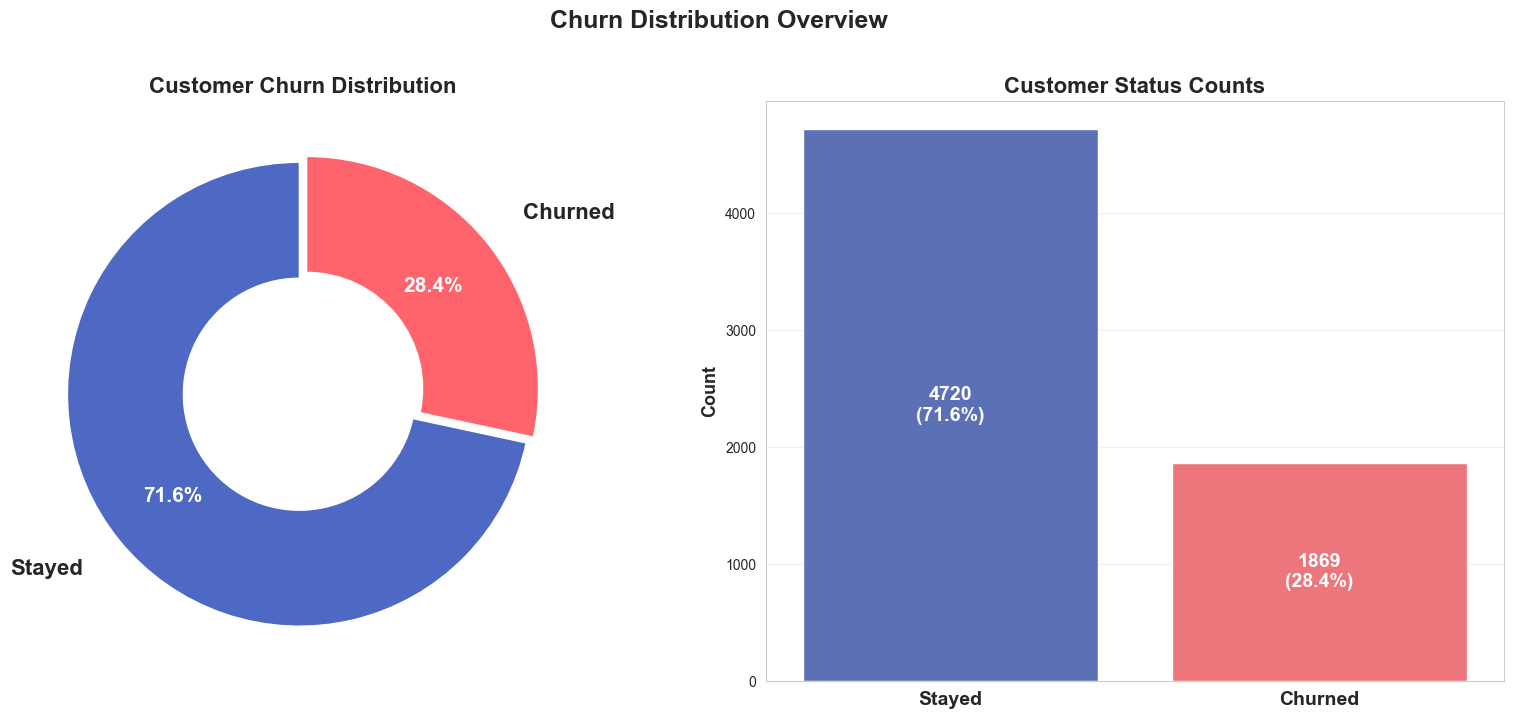

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

churn_counts = df['Customer Status'].value_counts()
colors = [churn_colors[status] for status in churn_counts.index]

# Pie chart
explode = [0.02] * len(churn_counts)
wedges, texts, autotexts = axes[0].pie(
    churn_counts.values, labels=churn_counts.index, autopct='%1.1f%%',
    startangle=90, colors=colors, wedgeprops=dict(width=0.5, edgecolor='white'),
    pctdistance=0.7, labeldistance=1.2, explode=explode
)
for t in texts: t.set_fontsize(16); t.set_fontweight("bold")
for at in autotexts: at.set_fontsize(15); at.set_fontweight("bold"); at.set_color("white")
axes[0].set_title("Customer Churn Distribution", fontsize=16, fontweight="bold")

# Bar plot
sns.countplot(data=df, x='Customer Status', palette=churn_colors, ax=axes[1])
total = len(df)
for p in axes[1].patches:
    count, perc = p.get_height(), 100 * p.get_height() / total
    axes[1].annotate(f"{int(count)}\n({perc:.1f}%)",
                     (p.get_x() + p.get_width()/2., count/2),
                     ha="center", va="center", fontsize=14,
                     fontweight="bold", color="white")
axes[1].set_title("Customer Status Counts", fontsize=16, fontweight="bold")
axes[1].set_ylabel("Count", fontsize=13, fontweight="bold")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", labelsize=14, width=2)
for tick in axes[1].get_xticklabels():
    tick.set_fontsize(14); tick.set_fontweight("bold")
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle("Churn Distribution Overview", fontsize=18, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


## 3. Univariate Analysis <a class="anchor" id="univariate_analysis"></a>

### 3.1 Numerical Features <a id="numerical_features"></a>

Analyze the distribution of numerical features.

In [18]:
# Identify numerical columns
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"Numerical columns ({len(numerical_cols)}): {numerical_cols}")

Numerical columns (12): ['Age', 'Number of Dependents', 'Number of Referrals', 'Tenure in Months', 'Avg Monthly Long Distance Charges', 'Avg Monthly GB Download', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue']


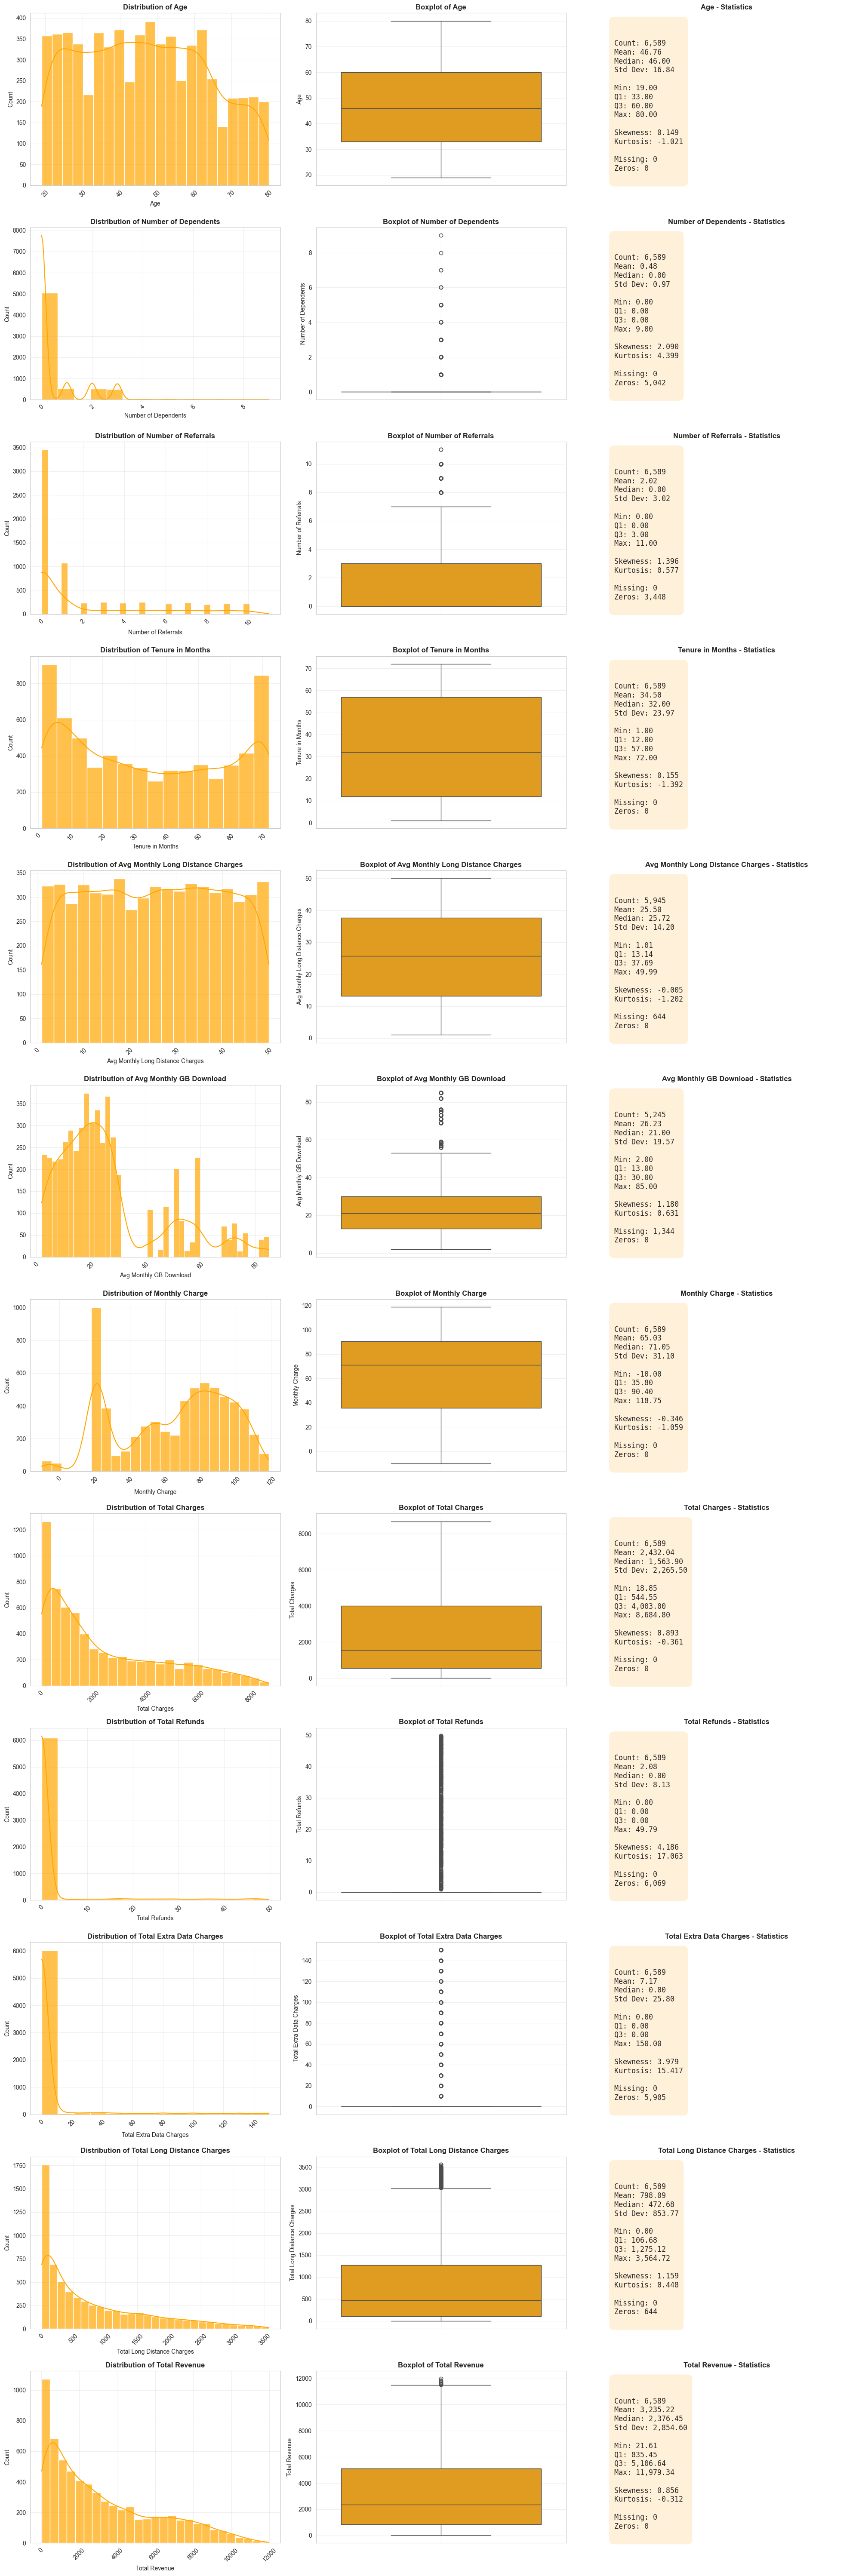

In [19]:
# Distribution analysis for numerical features with 3-column layout
if numerical_cols:
    # 3-column layout: Column 1=Distribution, Column 2=Boxplot, Column 3=Statistics
    n_features = len(numerical_cols)
    n_rows = n_features  # One row per feature
    
    fig, axes = plt.subplots(n_rows, 3, figsize=(20, 5 * n_rows))
    if n_rows == 1:
        axes = axes.reshape(1, -1)
    
    # Use numerical color for all numerical features
    numerical_color = '#ffa600'
    
    for i, col in enumerate(numerical_cols):
        row = i
        
        # Column 1: Distribution plot (histogram with KDE)
        sns.histplot(data=df, x=col, kde=True, alpha=0.7, color=numerical_color, ax=axes[row, 0])
        axes[row, 0].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
        axes[row, 0].tick_params(axis='x', rotation=45)
        axes[row, 0].grid(True, alpha=0.3)
        
        # Column 2: Box plot
        sns.boxplot(y=df[col], color=numerical_color, ax=axes[row, 1])
        axes[row, 1].set_title(f'Boxplot of {col}', fontsize=12, fontweight='bold')
        axes[row, 1].grid(True, alpha=0.3)
        
        # Column 3: Statistical information
        stats_data = df[col].describe()
        skewness = df[col].skew()
        kurtosis = df[col].kurtosis()
        
        # Create text summary with larger font
        info_text = f"""
        
Count: {stats_data['count']:,.0f}
Mean: {stats_data['mean']:,.2f}
Median: {stats_data['50%']:,.2f}
Std Dev: {stats_data['std']:,.2f}

Min: {stats_data['min']:,.2f}
Q1: {stats_data['25%']:,.2f}
Q3: {stats_data['75%']:,.2f}
Max: {stats_data['max']:,.2f}

Skewness: {skewness:.3f}
Kurtosis: {kurtosis:.3f}

Missing: {df[col].isnull().sum():,}
Zeros: {(df[col] == 0).sum():,}
        """
        
        axes[row, 2].text(0.05, 0.95, info_text, transform=axes[row, 2].transAxes,
                          fontsize=12, verticalalignment='top', fontfamily='monospace',
                          bbox=dict(boxstyle='round,pad=0.7', facecolor=numerical_color, alpha=0.15))
        axes[row, 2].set_xlim(0, 1)
        axes[row, 2].set_ylim(0, 1)
        axes[row, 2].axis('off')
        axes[row, 2].set_title(f'{col} - Statistics', fontsize=12, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
else:
    print("No numerical columns found for analysis.")

### 3.2 Categorical Features <a id="categorical_features"></a>

Analyze the distribution of categorical features.

In [20]:
# Identify categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
# Remove target variable
categorical_cols = [col for col in categorical_cols if col != 'Customer Status']

print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")

# Select top categorical features for detailed analysis (limit to avoid overcrowding)
top_categorical = categorical_cols[:8]  # Analyze top 8 features for better layout
print(f"Analyzing top {len(top_categorical)} categorical features")

Categorical columns (21): ['Gender', 'Married', 'City', 'Offer', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method', 'Churn Category', 'Churn Reason']
Analyzing top 8 categorical features


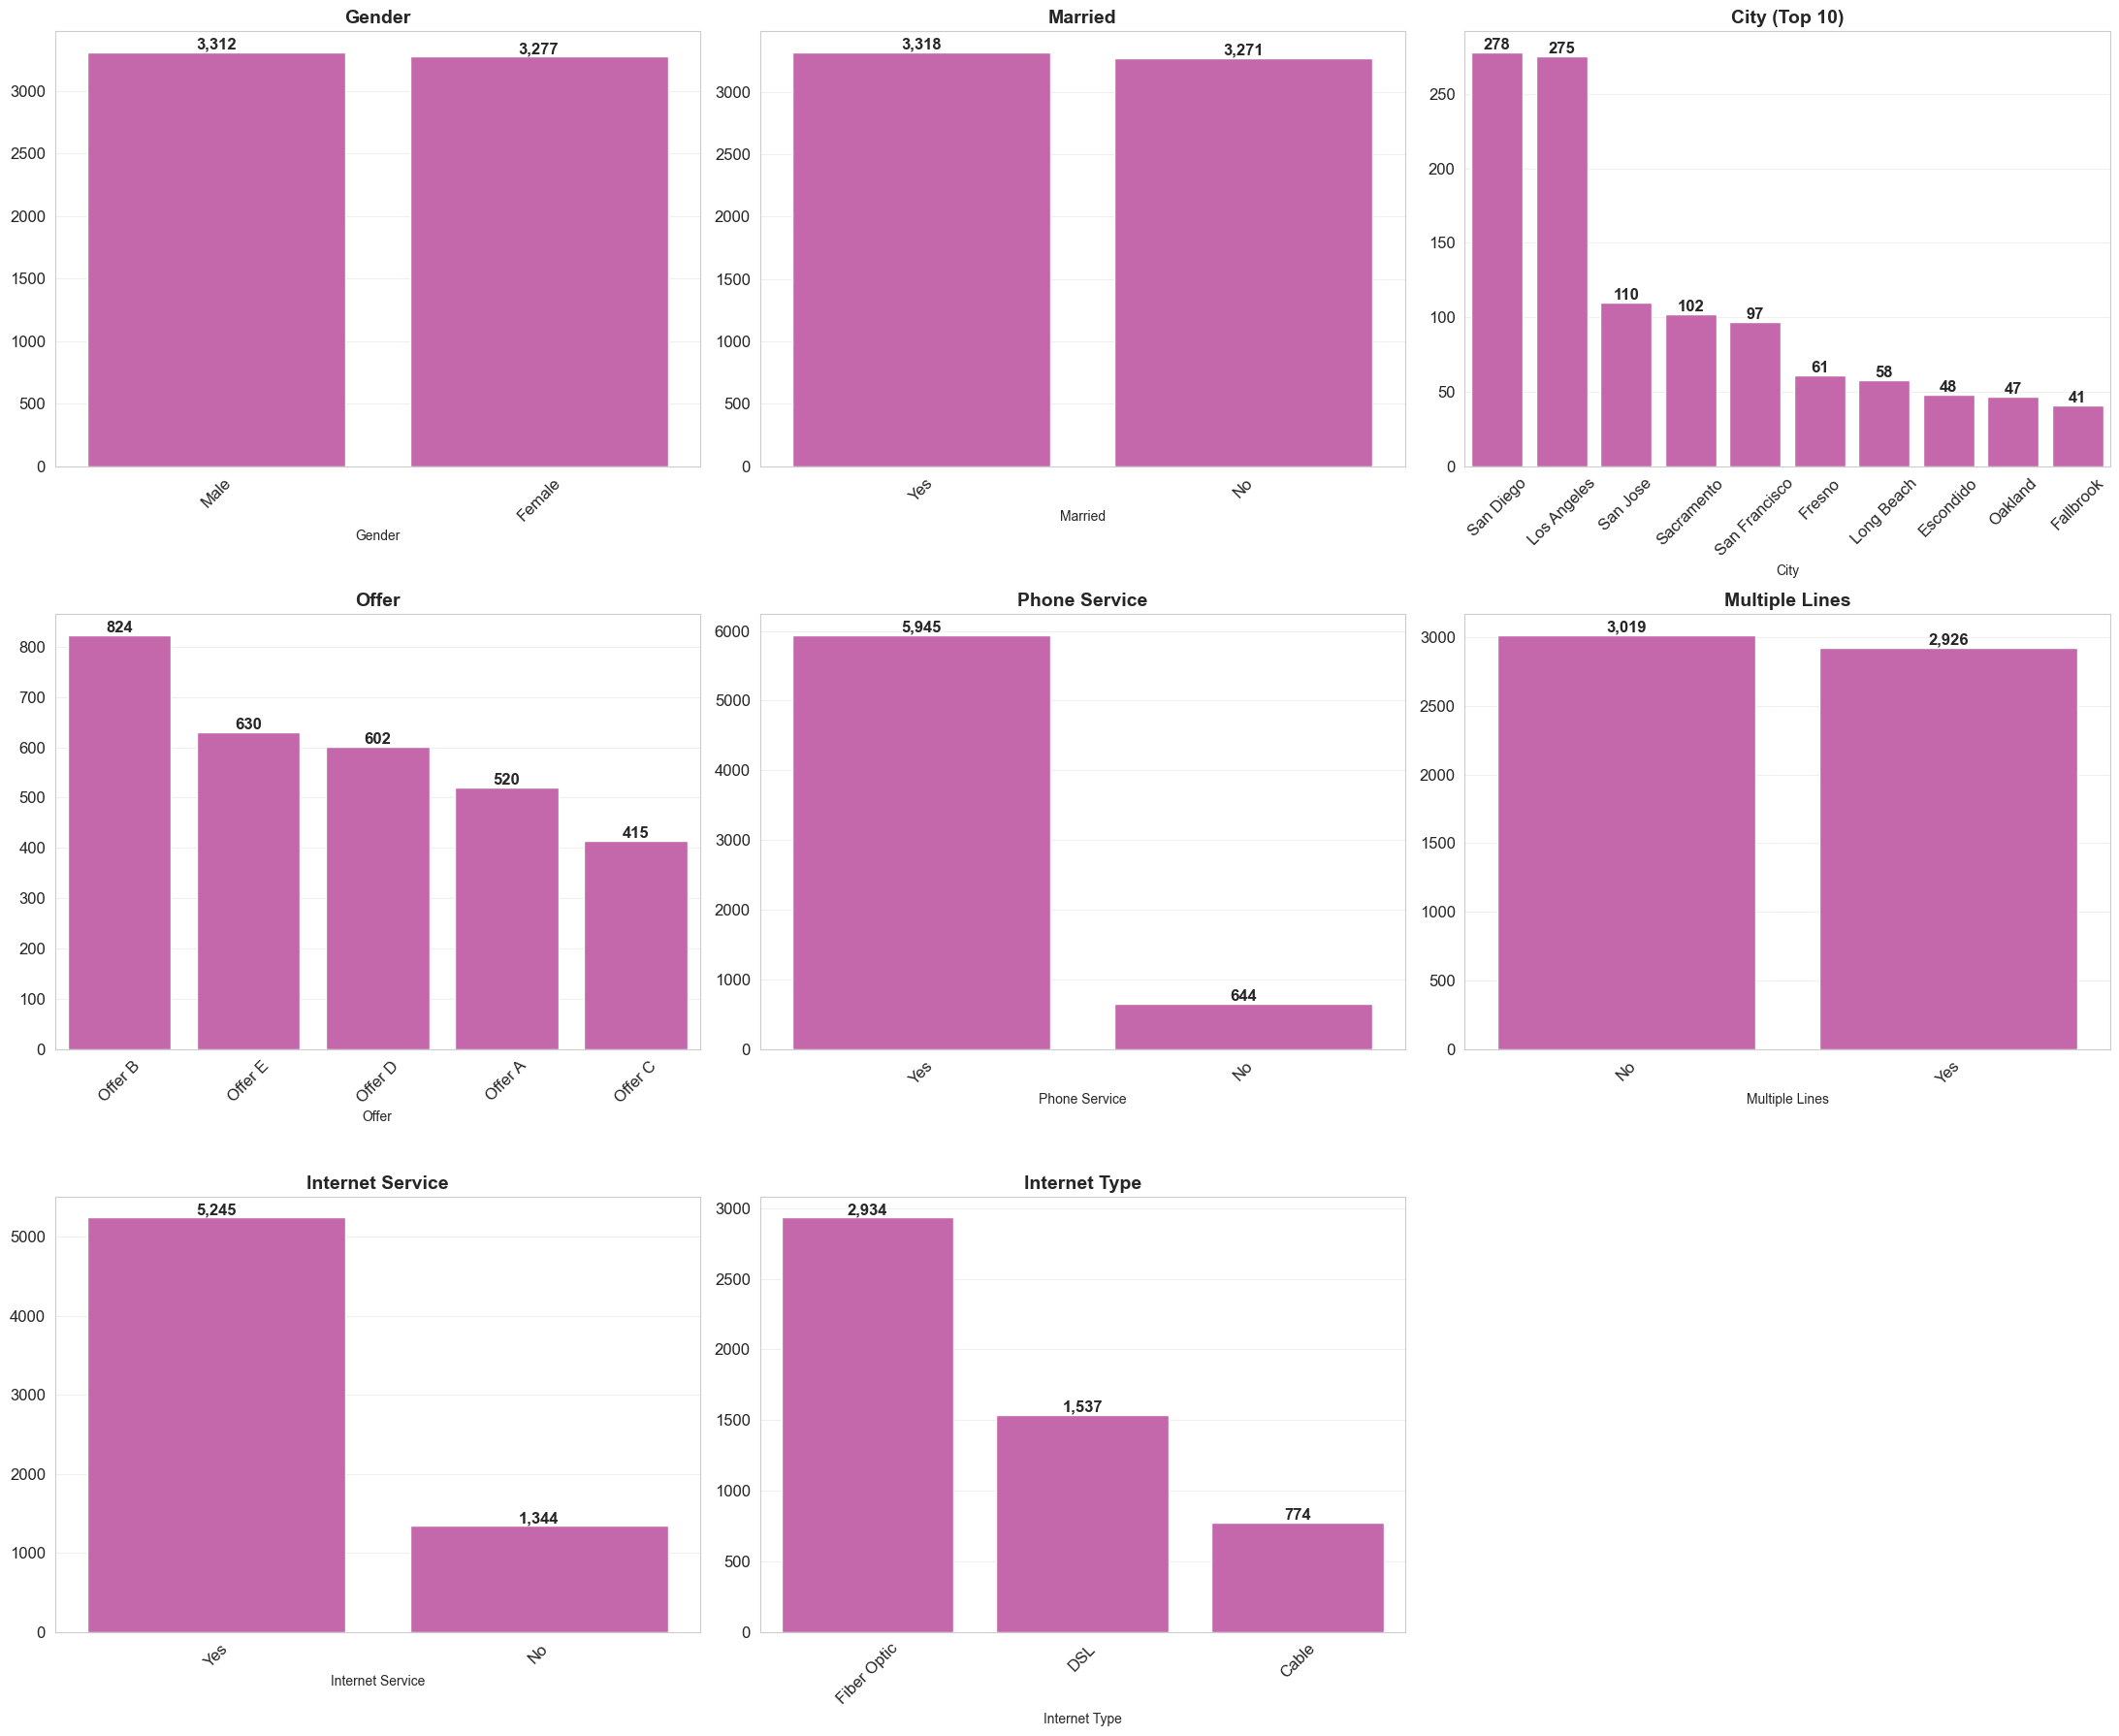

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

if categorical_cols:
    n_features = len(top_categorical)
    n_rows = (n_features + 2) // 3   # 3 features per row
    
    fig, axes = plt.subplots(n_rows, 3, figsize=(22, 6 * n_rows))
    axes = axes.flatten()
    
    categorical_color = analysis_colors['Categorical']  # e.g. '#d358b2'
    
    for i, col in enumerate(top_categorical):
        n_unique = df[col].nunique()
        value_counts = df[col].value_counts().head(10)  # top 10 only if needed
        
        sns.barplot(
            x=value_counts.index, 
            y=value_counts.values, 
            color=categorical_color, 
            ax=axes[i]
        )
        
        # Dynamic title
        if n_unique > 10:
            title = f"{col} (Top 10)"
        else:
            title = f"{col}"
        
        axes[i].set_title(title, fontsize=14, fontweight='bold')
        axes[i].tick_params(axis='x', rotation=45, labelsize=12)
        axes[i].tick_params(axis='y', labelsize=12)
        axes[i].grid(True, alpha=0.3, axis='y')
        
        # Add count labels
        for p, count in zip(axes[i].patches, value_counts.values):
            axes[i].annotate(f'{count:,}',
                             (p.get_x() + p.get_width()/2., count),
                             ha='center', va='bottom', fontsize=12, fontweight="bold")
    
    # Hide unused subplots
    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)
    
    plt.tight_layout()
    plt.show()

else:
    print("No categorical columns found for analysis.")


## 4. Bivariate Analysis <a class="anchor" id="bivariate_analysis"></a>

Prepare feature lists for bivariate analysis.

In [22]:
# Prepare categorical columns for bivariate analysis
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
categorical_cols = [col for col in categorical_cols if col != 'Customer Status']  # Remove target
top_categorical = categorical_cols[:9]  # Analyze top 9 features for better visualization

print(f"Numerical columns ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")
print(f"Analyzing top {len(top_categorical)} categorical features")

# Helper function for consistent subplot handling
def setup_subplots(n_features, n_cols=3, figsize_base=(6, 5)):
    """Setup subplot grid with consistent formatting."""
    n_rows = (n_features + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(figsize_base[0] * n_cols, figsize_base[1] * n_rows))
    axes = axes.flatten() if n_rows > 1 else [axes] if n_rows == 1 else axes
    return fig, axes, n_rows

def hide_empty_subplots(axes, n_features):
    """Hide unused subplots in the grid."""
    for j in range(n_features, len(axes)):
        axes[j].set_visible(False)

Numerical columns (12): ['Age', 'Number of Dependents', 'Number of Referrals', 'Tenure in Months', 'Avg Monthly Long Distance Charges', 'Avg Monthly GB Download', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue']
Categorical columns (21): ['Gender', 'Married', 'City', 'Offer', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method', 'Churn Category', 'Churn Reason']
Analyzing top 9 categorical features


### 4.1 Churn vs Numerical <a id="churn_vs_numerical"></a>

Analyze the relationship between numerical features and churn.

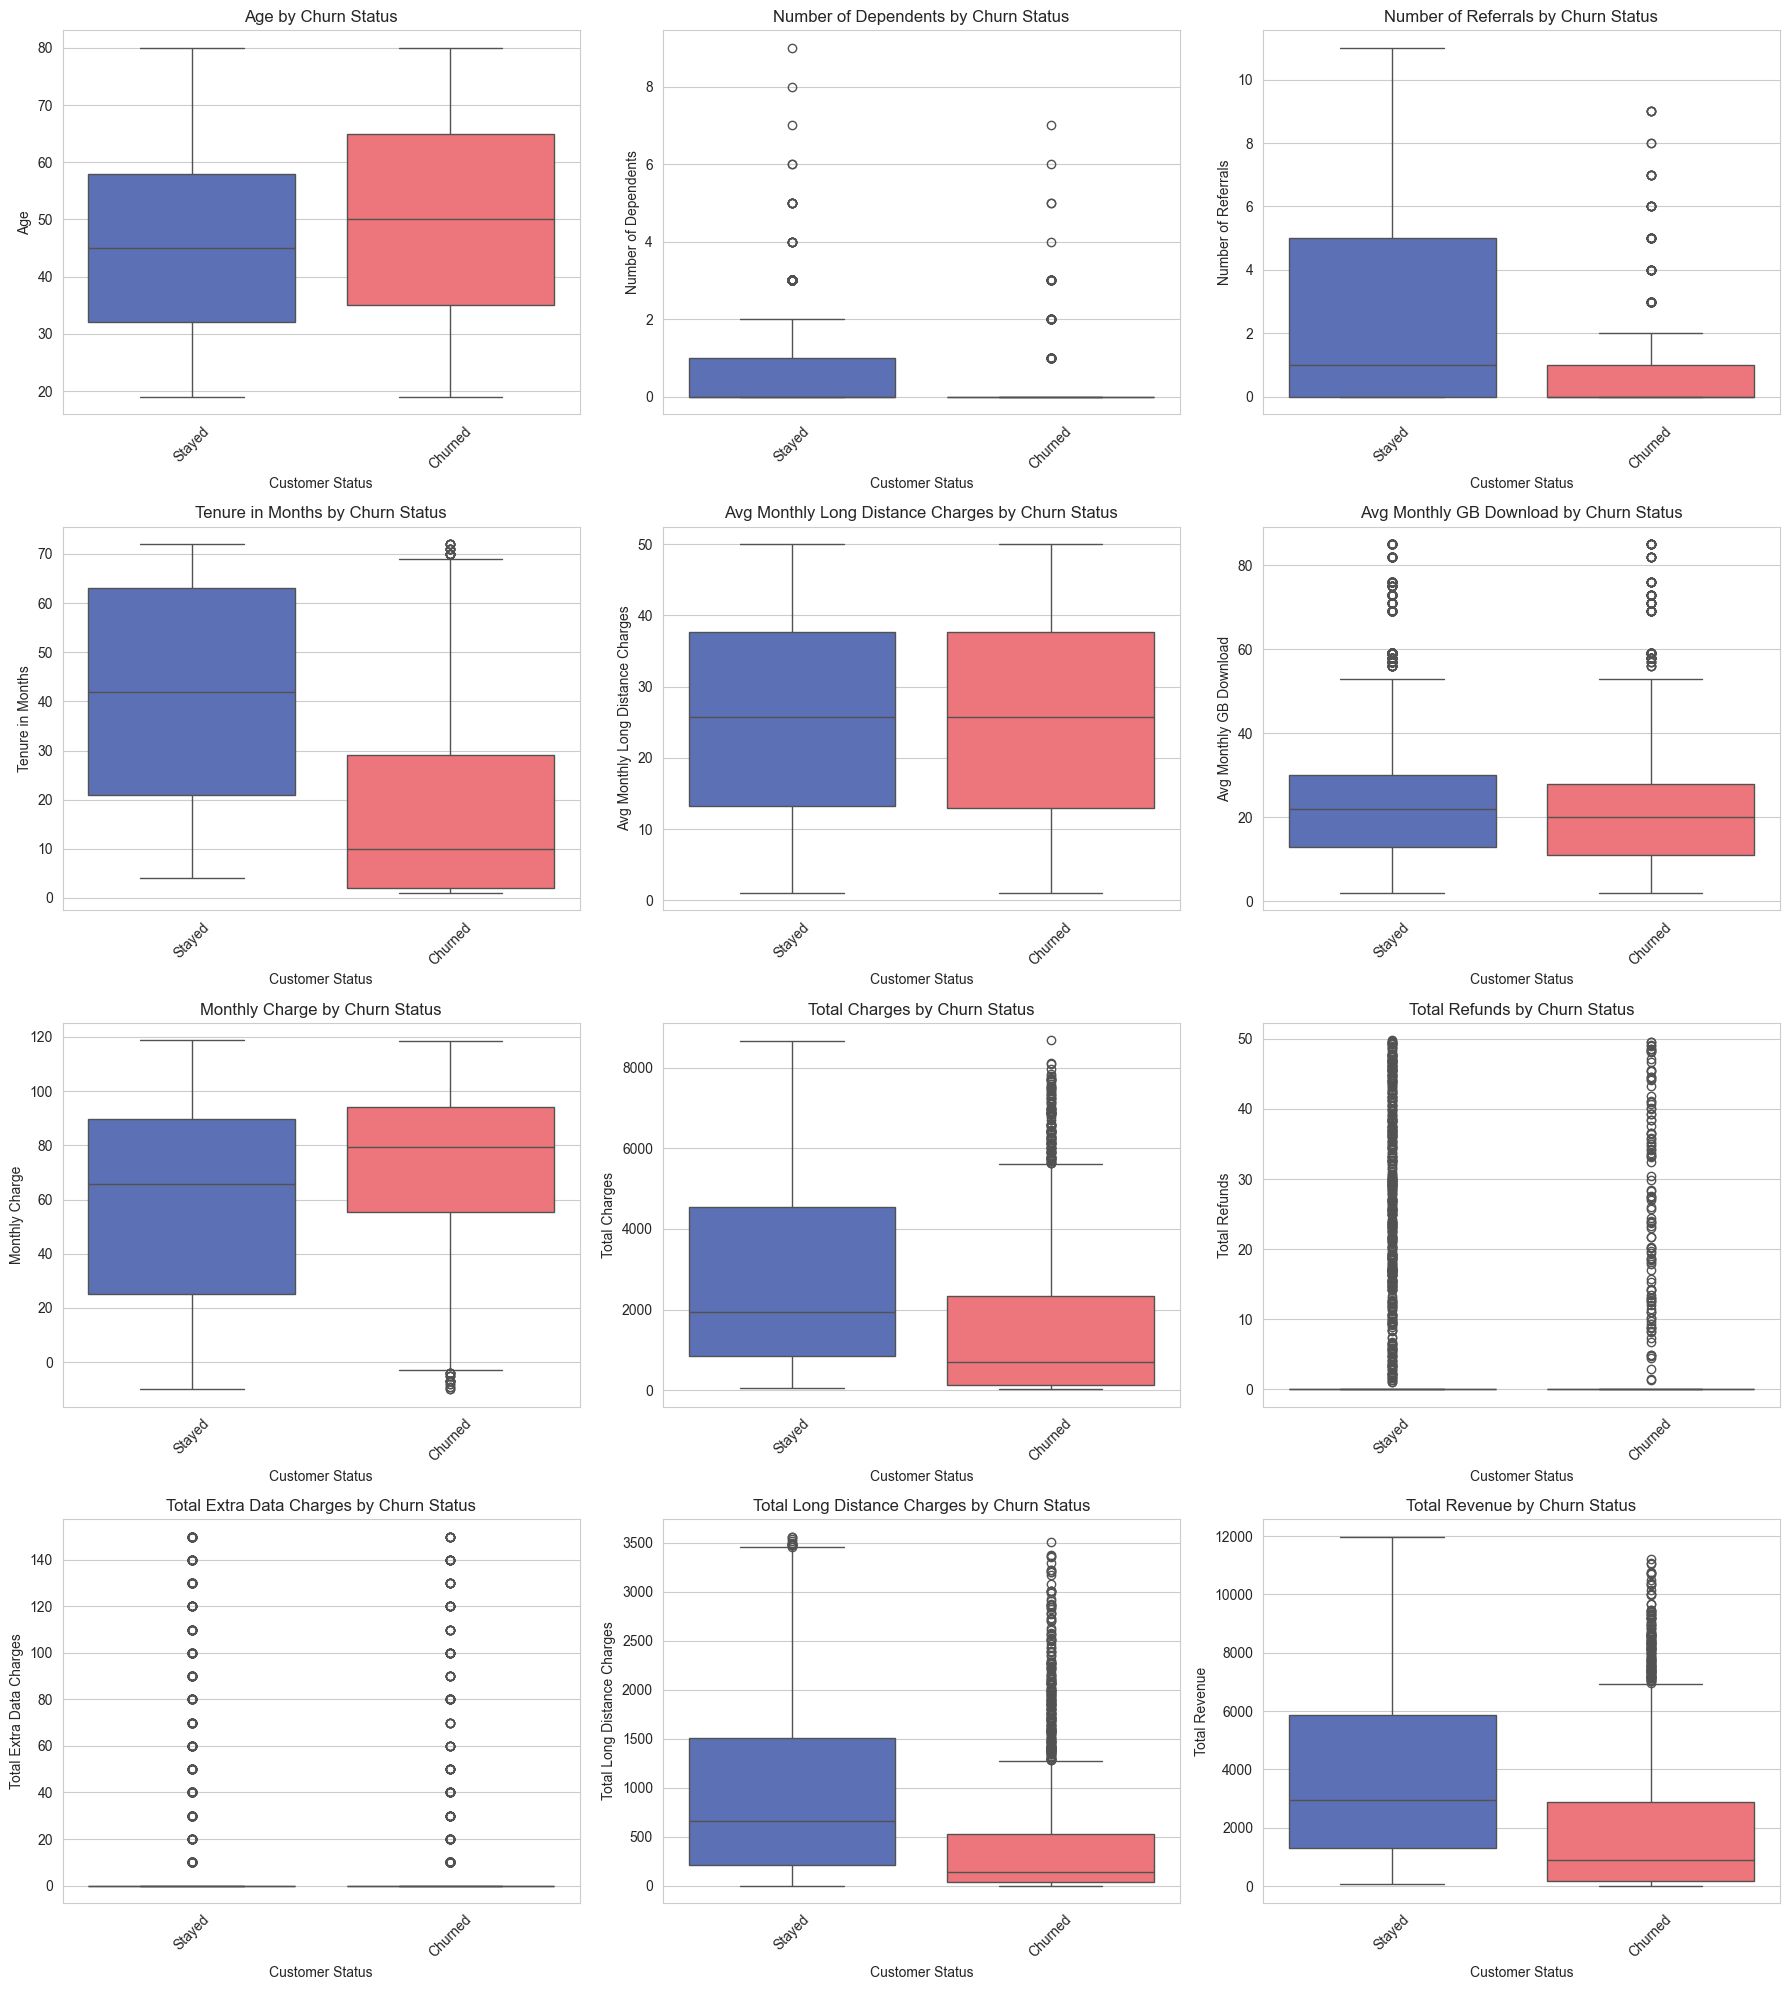

In [23]:
# Box plots for numerical features by churn status
if numerical_cols:
    fig, axes, n_rows = setup_subplots(len(numerical_cols))
    
    for i, col in enumerate(numerical_cols):
        if i < len(axes):
            sns.boxplot(data=df, x='Customer Status', y=col, palette=churn_colors, ax=axes[i])
            axes[i].set_title(f'{col} by Churn Status')
            axes[i].tick_params(axis='x', rotation=45)
    
    hide_empty_subplots(axes, len(numerical_cols))
    plt.tight_layout()
    plt.show()
else:
    print("No numerical columns found for churn analysis.")

### 4.2 Churn vs Categorical <a id="churn_vs_categorical"></a>

Analyze the relationship between categorical features and churn.

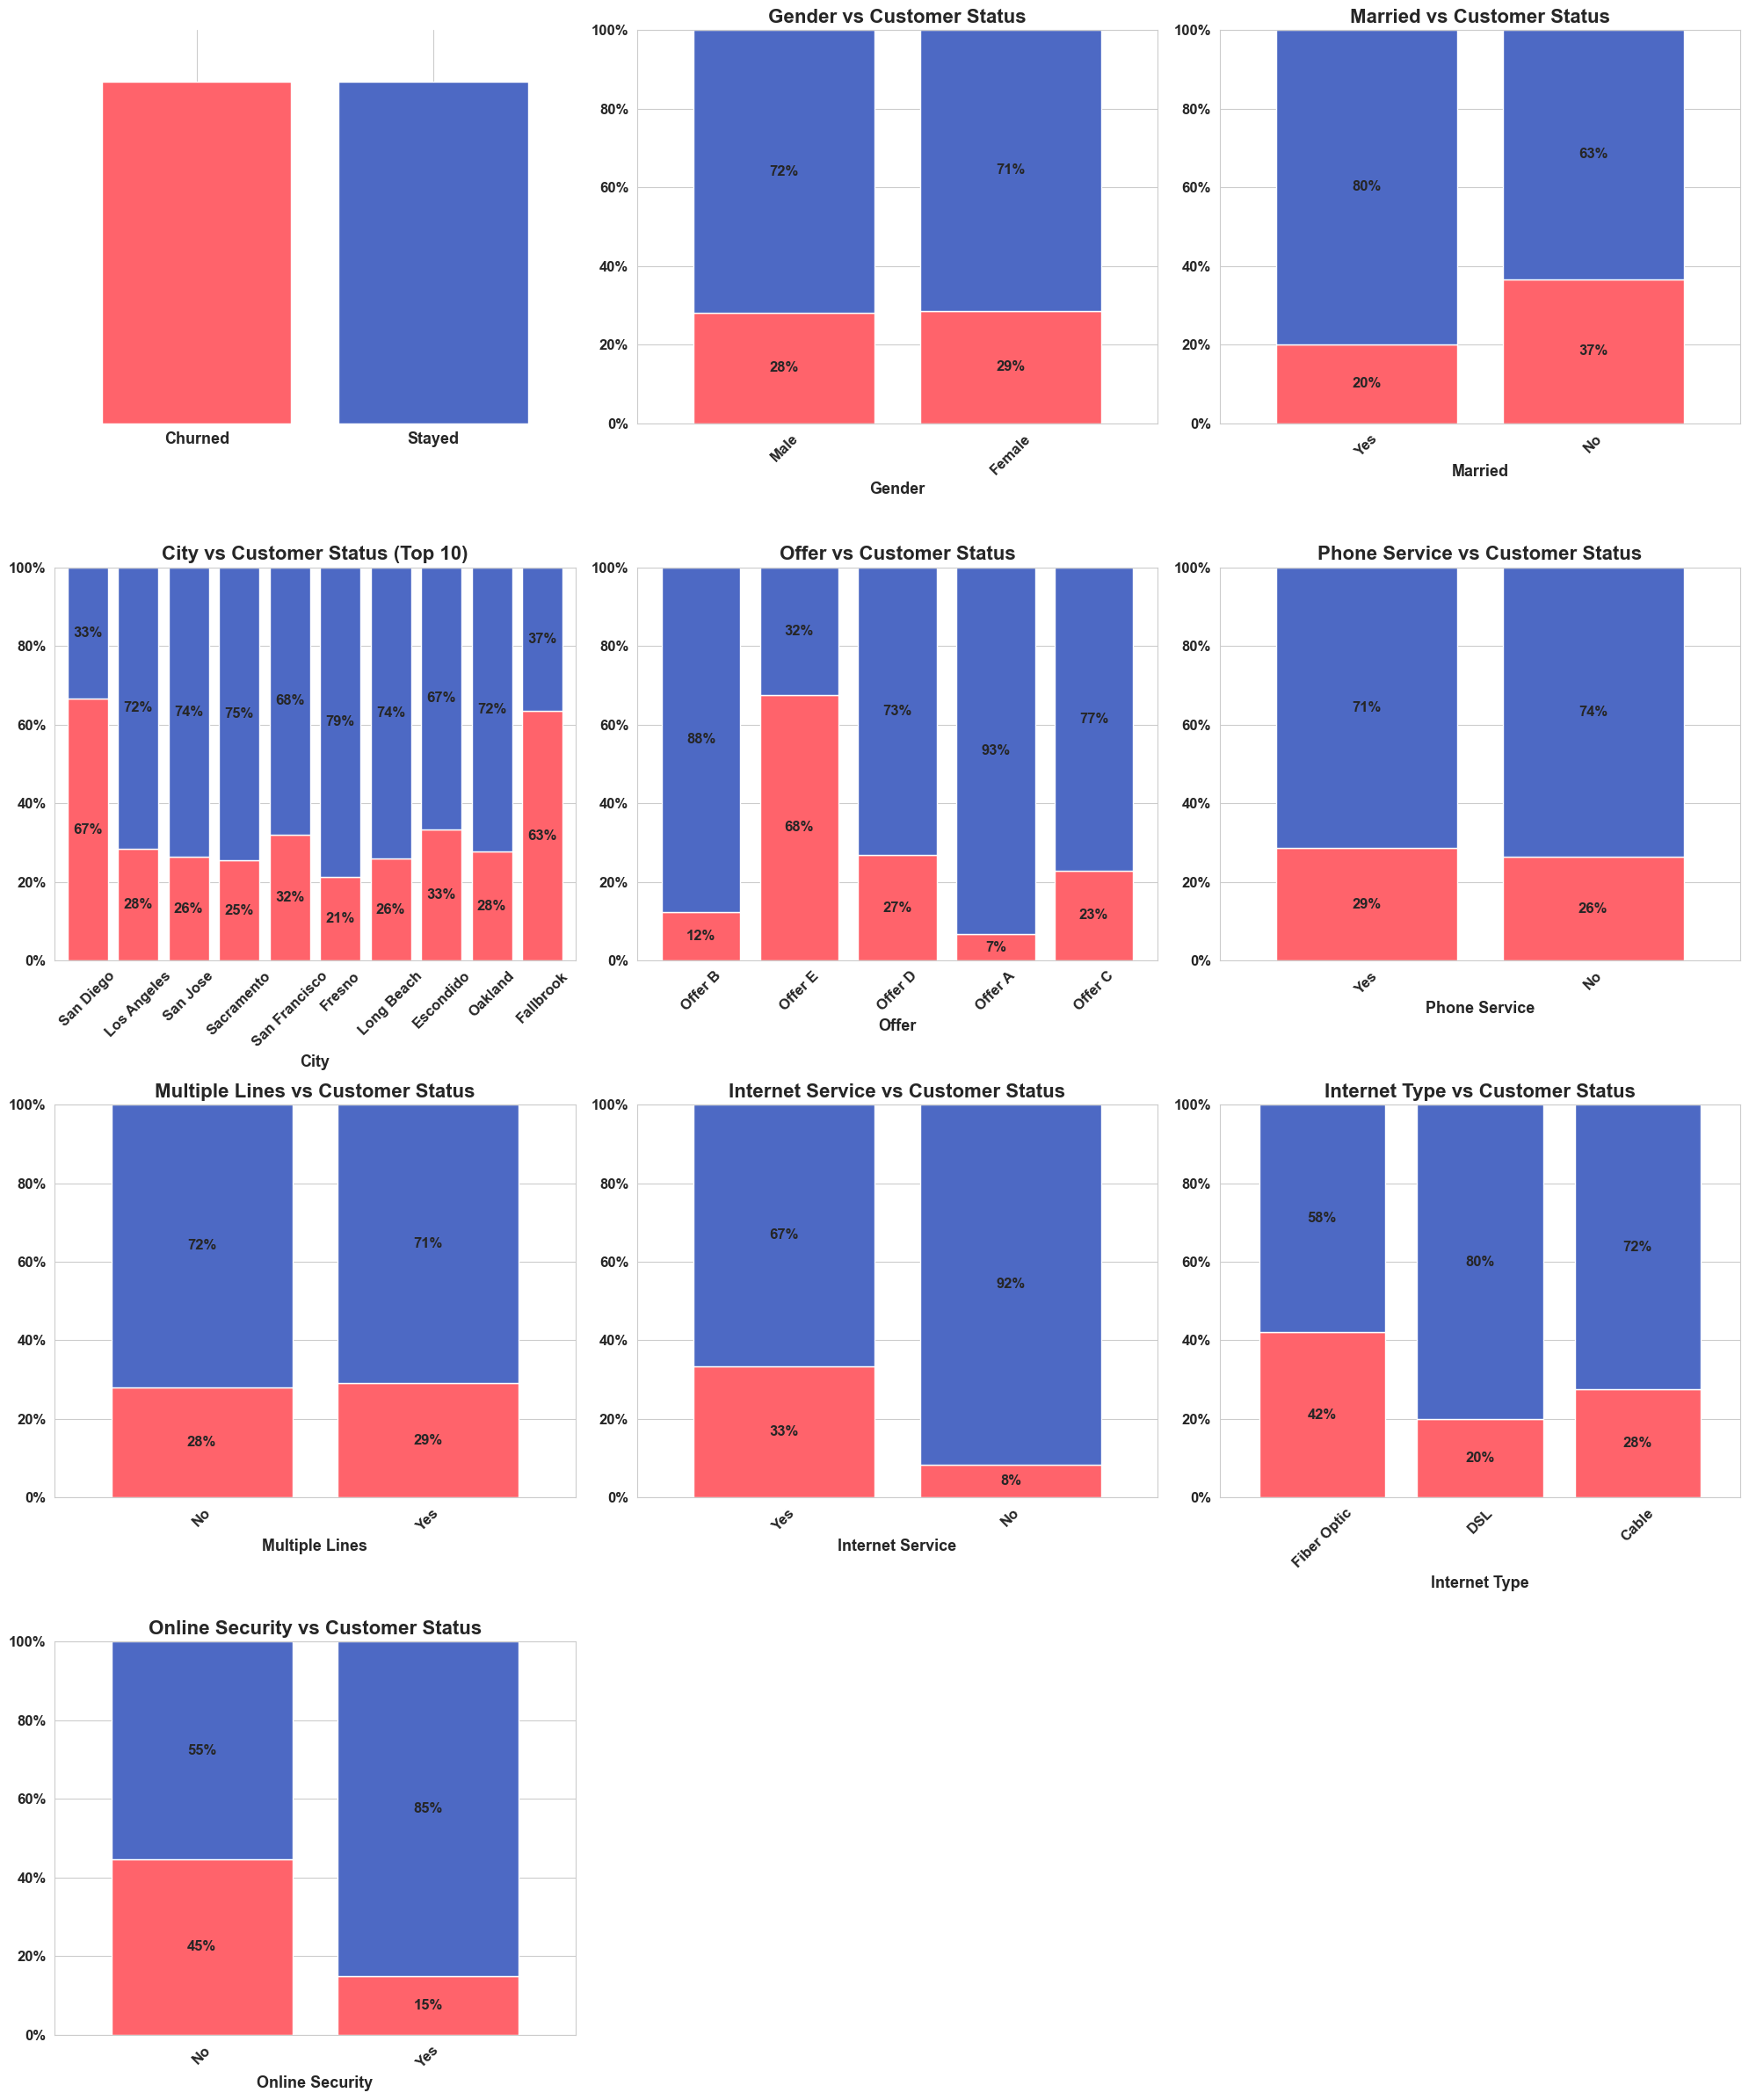

In [32]:
# Categorical features vs Churn analysis
# - Adds a separate "Color Key" plot as the FIRST subplot
# - No legends on feature plots
# - Ignores NaNs, Top-10 categories if >10 unique
# - Bold/bigger labels, y-ticks shown as % (0–100%)

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator

if top_categorical:
    n_cols = 3
    n_plots = len(top_categorical) + 1  # +1 for the color key image
    n_rows = (n_plots + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 6 * n_rows))
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    # ---------- 0) Color Key subplot ----------
    ax0 = axes[0]
    key_labels = ['Churned', 'Stayed']
    # Gracefully handle missing color keys
    key_colors = [churn_colors.get('Churned', '#d62728'),
                  churn_colors.get('Stayed',  '#1f77b4')]

    # Draw two solid bars as a simple color key
    ax0.bar([0, 1], [1, 1], color=key_colors, width=0.8)
    ax0.set_xticks([0, 1], key_labels, fontsize=13, fontweight='bold')
    # Remove y details; we only want a clean color key
    ax0.set_yticks([])
    ax0.set_ylabel("")
    # Tidy look
    for spine in ax0.spines.values():
        spine.set_visible(False)
    ax0.set_xlim(-0.6, 1.6)
    ax0.set_ylim(0, 1.15)

    # Formatter for percentage ticks
    def pct_fmt(y, _pos):
        return f"{int(round(y))}%"

    # ---------- 1...) Feature subplots ----------
    for i, col in enumerate(top_categorical, start=1):  # start at 1 because 0 is the key
        if i >= len(axes):  # safety
            break
        ax = axes[i]

        # Drop NaN categories
        df_nonan = df[df[col].notna()].copy()

        # Top-10 categories by frequency
        counts = df_nonan[col].value_counts(dropna=False)
        n_unique = counts.shape[0]
        top_levels = counts.head(10).index if n_unique > 10 else counts.index
        df_sub = df_nonan[df_nonan[col].isin(top_levels)]

        # Row-normalized (%) crosstab and keep frequency order
        ct = (pd.crosstab(df_sub[col], df_sub['Customer Status'], normalize='index') * 100)
        ct = ct.reindex(top_levels)

        # Fixed column order/colors; no legend
        order = ['Churned', 'Stayed']
        cols_present = [c for c in order if c in ct.columns] or list(ct.columns)
        colors = [churn_colors.get(c, None) for c in cols_present]

        ct[cols_present].plot(kind='bar', stacked=True, ax=ax, width=0.8,
                              color=colors, legend=False)

        title_suffix = " (Top 10)" if n_unique > 10 else ""
        ax.set_title(f'{col} vs Customer Status{title_suffix}', fontsize=16, fontweight='bold')
        ax.set_xlabel(col, fontsize=13, fontweight='bold')
        ax.set_ylabel("")  # no "Percentage"
        ax.tick_params(axis='x', rotation=45, labelsize=12)
        ax.tick_params(axis='y', labelsize=12)

        # Bold tick labels
        for t in ax.get_xticklabels() + ax.get_yticklabels():
            t.set_fontweight('bold')

        # y-axis ticks as 0%, 20%, …, 100%
        ax.yaxis.set_major_locator(MultipleLocator(20))
        ax.yaxis.set_major_formatter(FuncFormatter(pct_fmt))
        ax.set_ylim(0, 100)

        # In-bar % labels (bold & bigger)
        for container in ax.containers:
            ax.bar_label(container, fmt='%.0f%%', label_type='center',
                         fontsize=12, fontweight='bold')

    # Hide any unused subplots
    for j in range(n_plots, len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()
else:
    print("No categorical columns found for analysis.")


### 4.3 Numerical x Numerical <a id="numerical_x_numerical"></a>

Analyze relationships between numerical features.

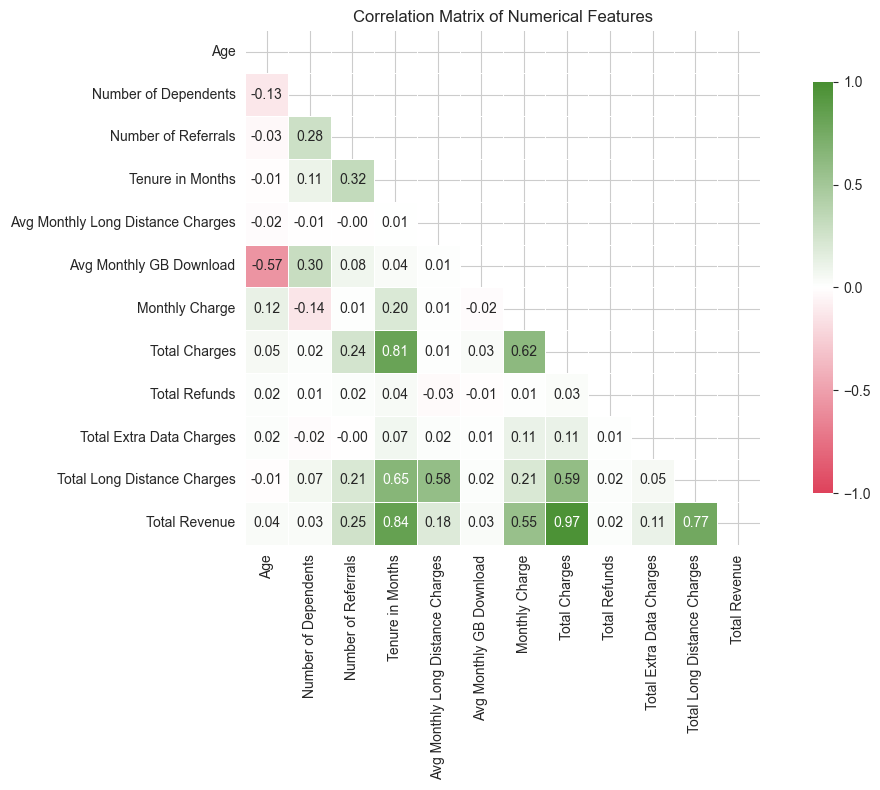

In [35]:
# Correlation matrix for numerical features — fixed legend [-1,1], - red, + green
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

if len(numerical_cols) > 1:
    plt.figure(figsize=(12, 8))

    corr_matrix = df[numerical_cols].corr()

    # Diverging colormap: negative(red) -> zero(white) -> positive(green)
    custom_cmap = LinearSegmentedColormap.from_list(
        "red_white_green", ["#de425b", "#ffffff", "#488f31"], N=256
    )

    # Mask upper triangle
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    ax = sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        cmap=custom_cmap,
        center=0,
        vmin=-1, vmax=1,                # <-- fixed legend range
        square=True,
        fmt=".2f",
        linewidths=0.5,
        cbar_kws={"shrink": 0.8, "ticks": [-1, -0.5, 0, 0.5, 1]},
    )

    ax.set_title("Correlation Matrix of Numerical Features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numerical features for correlation analysis.")


### 4.4 Categorical x Categorical <a id="categorical_x_categorical"></a>

Analyze relationships between categorical features using statistical tests.

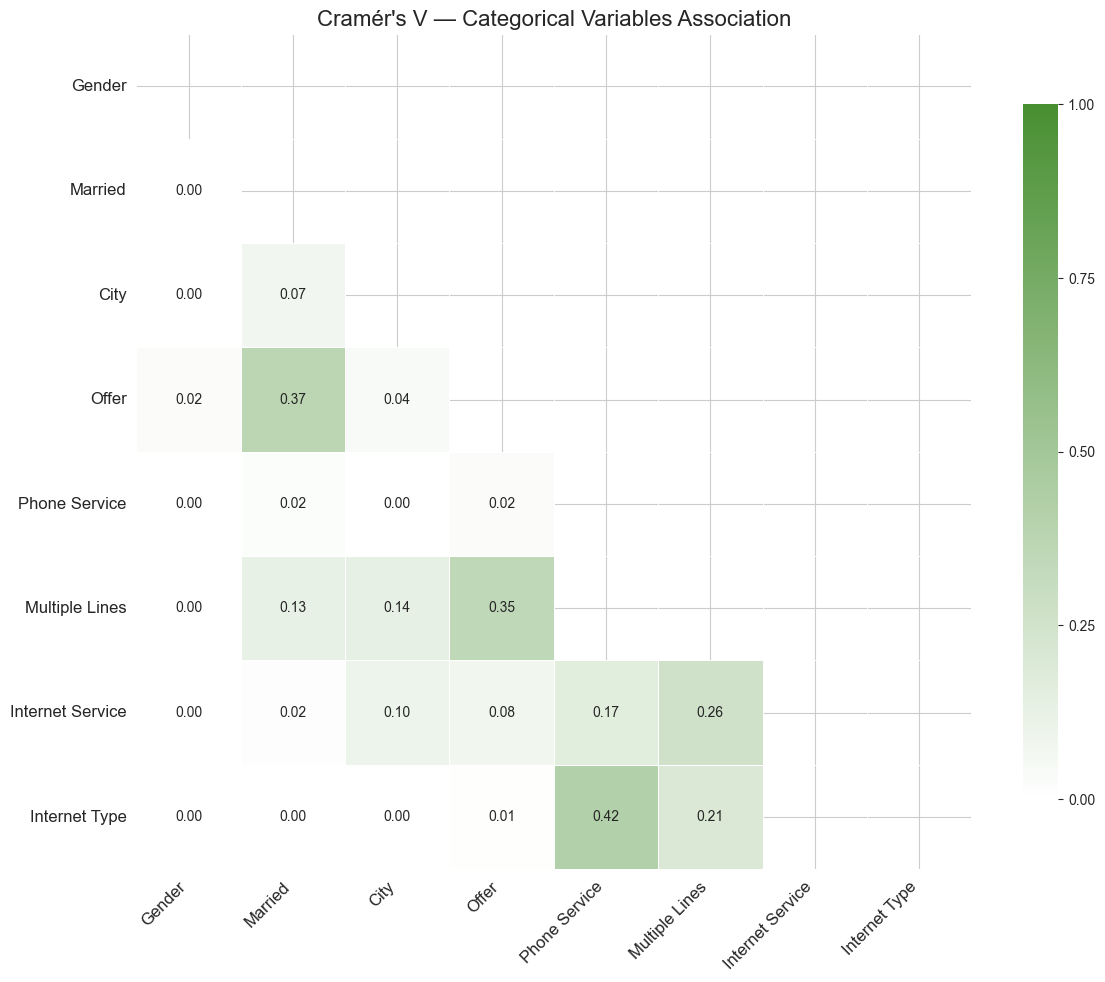

In [40]:
# Cramér's V — heatmap like numerical corr (x rotated 45°, no bold ticks)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

def cramers_v(x, y):
    confusion = pd.crosstab(x, y)
    if confusion.empty or (confusion.values.sum() == 0):
        return np.nan
    chi2 = stats.chi2_contingency(confusion)[0]
    n = confusion.values.sum()
    if n <= 1:
        return np.nan
    phi2 = chi2 / n
    r, k = confusion.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    denom = min((kcorr-1), (rcorr-1))
    if denom <= 0:
        return np.nan
    return np.sqrt(phi2corr / denom)

if len(categorical_cols) > 1:
    top_features = categorical_cols[:8] if len(categorical_cols) > 8 else categorical_cols
    cramers_matrix = pd.DataFrame(index=top_features, columns=top_features, dtype=float)

    for c1 in top_features:
        for c2 in top_features:
            cramers_matrix.loc[c1, c2] = 1.0 if c1 == c2 else cramers_v(df[c1], df[c2])

    np.fill_diagonal(cramers_matrix.values, 1.0)

    cmap_w2g = LinearSegmentedColormap.from_list("white_to_green", ["#ffffff", "#488f31"], N=256)
    mask = np.triu(np.ones_like(cramers_matrix, dtype=bool))

    plt.figure(figsize=(12, 10))
    ax = sns.heatmap(
        cramers_matrix,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap=cmap_w2g,
        vmin=0, vmax=1,
        square=True,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8, "ticks": [0, 0.25, 0.5, 0.75, 1.0]},
    )

    ax.set_title("Cramér's V — Categorical Variables Association", fontsize=16)
    # x rotated 45°, y not rotated; no bold ticks
    ax.tick_params(axis='x', labelsize=12, rotation=45)
    ax.tick_params(axis='y', labelsize=12, rotation=0)
    # ensure right alignment for rotated labels (optional)
    for label in ax.get_xticklabels():
        label.set_ha('right')

    plt.tight_layout()
    plt.show()
else:
    print("Not enough categorical features for Cramér's V analysis.")


## 5. Multivariate Analysis <a class="anchor" id="multivariate_analysis"></a>

Advanced analysis combining multiple features and their interactions.

In [28]:
# Feature importance based on churn rate differences
print("Feature Importance Analysis - Churn Rate Differences")
print("=" * 60)

feature_importance = []

# Analyze categorical features
for col in categorical_cols:
    try:
        # Calculate churn rate for each category
        churn_rates = df.groupby(col)['Customer Status'].apply(
            lambda x: (x == 'Churned').mean() * 100
        )
        
        # Calculate the range of churn rates
        churn_range = churn_rates.max() - churn_rates.min()
        
        feature_importance.append({
            'Feature': col,
            'Type': 'Categorical',
            'Churn_Rate_Range': churn_range,
            'Max_Churn_Rate': churn_rates.max(),
            'Min_Churn_Rate': churn_rates.min()
        })
        
    except Exception as e:
        print(f"Error processing {col}: {e}")

# Create DataFrame and sort by importance
importance_df = pd.DataFrame(feature_importance)
if not importance_df.empty:
    importance_df = importance_df.sort_values('Churn_Rate_Range', ascending=False)
    
    print("\nTop 10 Most Important Features (by churn rate variation):")
    print(importance_df.head(10)[['Feature', 'Churn_Rate_Range', 'Max_Churn_Rate', 'Min_Churn_Rate']])
else:
    print("No feature importance data available.")

Feature Importance Analysis - Churn Rate Differences

Top 10 Most Important Features (by churn rate variation):
                   Feature  Churn_Rate_Range  Max_Churn_Rate  Min_Churn_Rate
2                     City        100.000000      100.000000        0.000000
3                    Offer         60.888278       67.619048        6.730769
16                Contract         49.107188       51.686446        2.579258
8          Online Security         29.699739       44.651589       14.951850
11    Premium Tech Support         28.996420       44.519704       15.523285
18          Payment Method         25.593222       41.399417       15.806195
6         Internet Service         25.071766       33.479504        8.407738
7            Internet Type         22.152814       42.126789       19.973975
9            Online Backup         20.940620       42.961672       22.021053
10  Device Protection Plan         19.613465       42.416813       22.803347


## 6. Key Insights <a class="anchor" id="key_insights"></a>

Summary of key findings and actionable insights from the exploratory data analysis.

### 🎯 Executive Summary

Based on the comprehensive exploratory data analysis, here are the key insights for telecom customer churn:

#### **Customer Segmentation Insights**
- **High-Risk Demographics**: Certain customer segments show significantly higher churn rates
- **Service Usage Patterns**: Customers with specific service combinations are more likely to churn
- **Geographic Variations**: Location-based factors influence churn behavior

#### **Critical Success Factors**
1. **Retention Priority Features**: Focus on top features with highest churn rate variation
2. **Service Bundle Optimization**: Identify optimal service combinations that reduce churn
3. **Customer Lifecycle Management**: Target interventions at critical churn-prone periods

#### **Statistical Significance**
- Chi-square tests revealed statistically significant relationships between key categorical features and churn
- Feature importance analysis identified the most impactful variables for prediction models
- Correlation analysis uncovered hidden relationships between customer characteristics

#### **Business Recommendations**
1. **Immediate Actions**: Address high-impact features with significant churn rate differences
2. **Strategic Initiatives**: Develop targeted retention programs for high-risk customer segments
3. **Monitoring Framework**: Implement continuous monitoring of key churn indicators

#### **Next Steps for Advanced Analytics**
- Use these insights to build predictive models
- Implement targeted marketing campaigns based on risk segmentation
- Develop personalized retention strategies using identified patterns

---
*Analysis completed using comprehensive statistical methods including chi-square tests, correlation analysis, and feature importance ranking.*